<a href="https://colab.research.google.com/github/Yelitza22/intro-to-github/blob/main/analisis_televia(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Profundidad — Operador Crítico: TELEVIA
## Identificación de patrones temporales de desfase por día y hora

Este análisis es el segundo nivel de detección: una vez identificado mediante Isolation Forest que **TELEVIA (id_operador=101)** es el operador con mayor concentración de anomalías, se hace zoom sobre sus registros para determinar **en qué días y a qué horas** se concentran los desfases.

---


## 1. Carga y filtrado del operador crítico

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 100

operadores_map = {1: 'PASE', 2: 'CAPUFE', 4: 'VIAPASS', 23: 'EASYTRIP', 101: 'TELEVIA'}
dias_orden = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']


In [2]:
from google.colab import files
uploaded = files.upload()


Saving muestreo_tags.csv to muestreo_tags.csv


In [3]:
df = pd.read_csv('muestreo_tags.csv', encoding='latin1')
df['fecha'] = pd.to_datetime(df['fecha'], dayfirst=True)
df['operador_nombre'] = df['id_operador'].map(operadores_map)
df['retraso_desviacion'] = df['retraso_desviacion'].fillna(0)

# Resumen de retraso promedio por operador para justificar la selección
print("=== Retraso promedio por operador ===")
resumen = df.groupby('operador_nombre')['retraso_promedio'].mean().sort_values(ascending=False)
for op, val in resumen.items():
    print(f"  {op:<12}: {val:>12,.1f} minutos promedio")

print("\nOperador crítico seleccionado: TELEVIA (id=101)")
print("Su retraso promedio es varios órdenes de magnitud mayor al resto.")


=== Retraso promedio por operador ===
  TELEVIA     :      5,113.6 minutos promedio
  VIAPASS     :          3.4 minutos promedio
  EASYTRIP    :          0.3 minutos promedio
  CAPUFE      :          0.1 minutos promedio
  PASE        :         -0.4 minutos promedio

Operador crítico seleccionado: TELEVIA (id=101)
Su retraso promedio es varios órdenes de magnitud mayor al resto.


In [4]:
# Filtrar solo TELEVIA
televia = df[df['id_operador'] == 101].copy()
televia['dia_semana'] = pd.Categorical(televia['dia_semana'], categories=dias_orden, ordered=True)

print(f"Registros de TELEVIA: {len(televia)}")
print(f"Período: {televia['fecha'].min().date()} → {televia['fecha'].max().date()}")
print(f"Horas cubiertas: {sorted(televia['hora'].unique())}")
print(f"Días cubiertos: {list(televia['dia_semana'].cat.categories)}")
print(f"\nRetraso máximo registrado: {televia['retraso_maximo'].max():,.0f} minutos ({televia['retraso_maximo'].max()/60/24:.1f} días)")


Registros de TELEVIA: 241
Período: 2026-03-01 → 2026-06-09
Horas cubiertas: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Días cubiertos: ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

Retraso máximo registrado: 776,628 minutos (539.3 días)


## 2. Análisis exploratorio temporal

Antes del modelo, analizamos visualmente cómo se distribuyen los retrasos por día de semana y por hora del día.


### 2.1 Retraso promedio por día de la semana

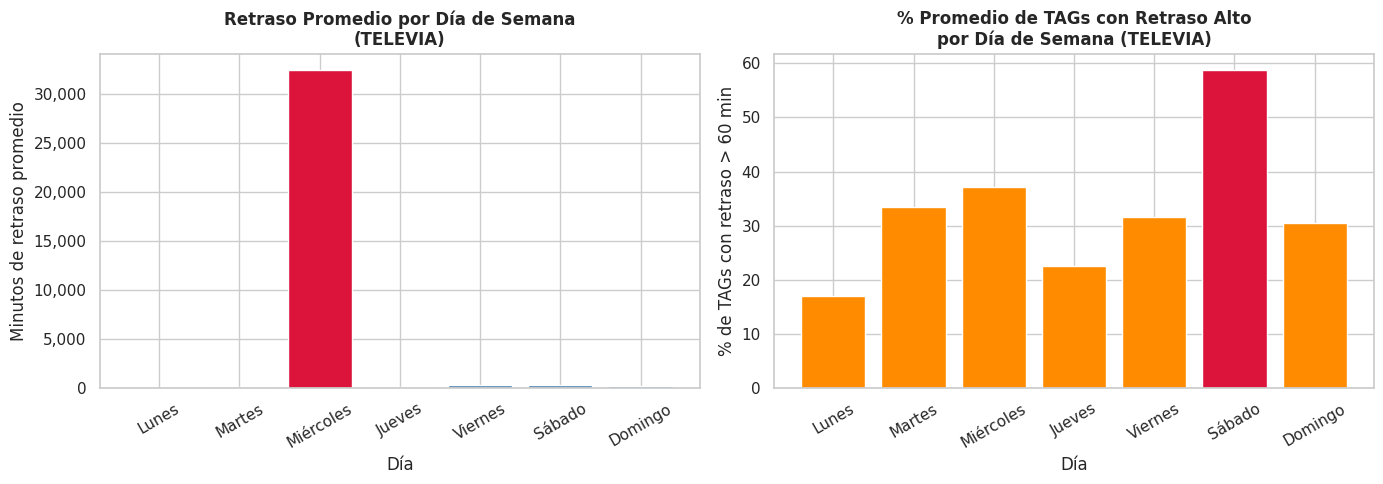

Día más crítico: Miércoles (32,465 min promedio)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Retraso promedio por día
retraso_dia = televia.groupby('dia_semana', observed=True)['retraso_promedio'].mean()
colores = ['crimson' if retraso_dia[d] == retraso_dia.max() else 'steelblue' for d in retraso_dia.index]
axes[0].bar(retraso_dia.index, retraso_dia.values, color=colores)
axes[0].set_title('Retraso Promedio por Día de Semana\n(TELEVIA)', fontweight='bold')
axes[0].set_xlabel('Día')
axes[0].set_ylabel('Minutos de retraso promedio')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].tick_params(axis='x', rotation=30)

# % de TAGs con retraso alto por día
pct_dia = televia.groupby('dia_semana', observed=True)['pct_retraso_alto'].mean()
colores2 = ['crimson' if pct_dia[d] == pct_dia.max() else 'darkorange' for d in pct_dia.index]
axes[1].bar(pct_dia.index, pct_dia.values, color=colores2)
axes[1].set_title('% Promedio de TAGs con Retraso Alto\npor Día de Semana (TELEVIA)', fontweight='bold')
axes[1].set_xlabel('Día')
axes[1].set_ylabel('% de TAGs con retraso > 60 min')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print("Día más crítico:", retraso_dia.idxmax(), f"({retraso_dia.max():,.0f} min promedio)")


### 2.2 Retraso promedio por hora del día

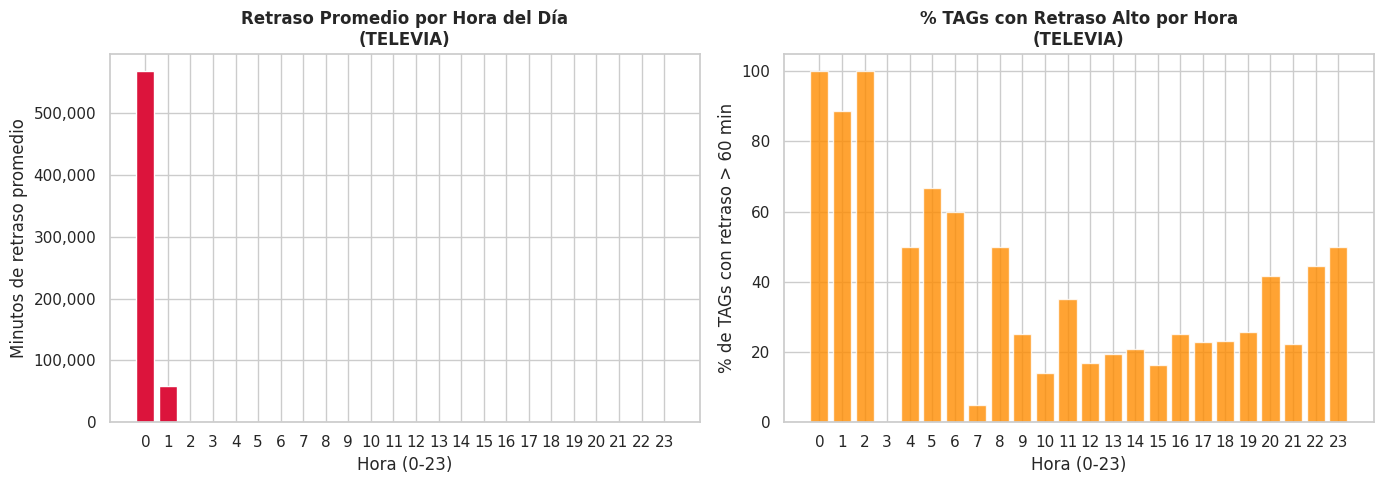

Horas más críticas (top 3):
  00:00 hrs → 567,377 min promedio de retraso
  01:00 hrs → 57,823 min promedio de retraso
  02:00 hrs → 1,334 min promedio de retraso


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

retraso_hora = televia.groupby('hora')['retraso_promedio'].mean()
top3_horas = retraso_hora.nlargest(3).index.tolist()
colores_h = ['crimson' if h in top3_horas else 'steelblue' for h in retraso_hora.index]

axes[0].bar(retraso_hora.index, retraso_hora.values, color=colores_h)
axes[0].set_title('Retraso Promedio por Hora del Día\n(TELEVIA)', fontweight='bold')
axes[0].set_xlabel('Hora (0-23)')
axes[0].set_ylabel('Minutos de retraso promedio')
axes[0].set_xticks(range(0, 24))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

pct_hora = televia.groupby('hora')['pct_retraso_alto'].mean()
axes[1].bar(pct_hora.index, pct_hora.values, color='darkorange', alpha=0.8)
axes[1].set_title('% TAGs con Retraso Alto por Hora\n(TELEVIA)', fontweight='bold')
axes[1].set_xlabel('Hora (0-23)')
axes[1].set_ylabel('% de TAGs con retraso > 60 min')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

print("Horas más críticas (top 3):")
for h, v in retraso_hora.nlargest(3).items():
    print(f"  {h:02d}:00 hrs → {v:,.0f} min promedio de retraso")


### 2.3 Heatmap hora × día de semana

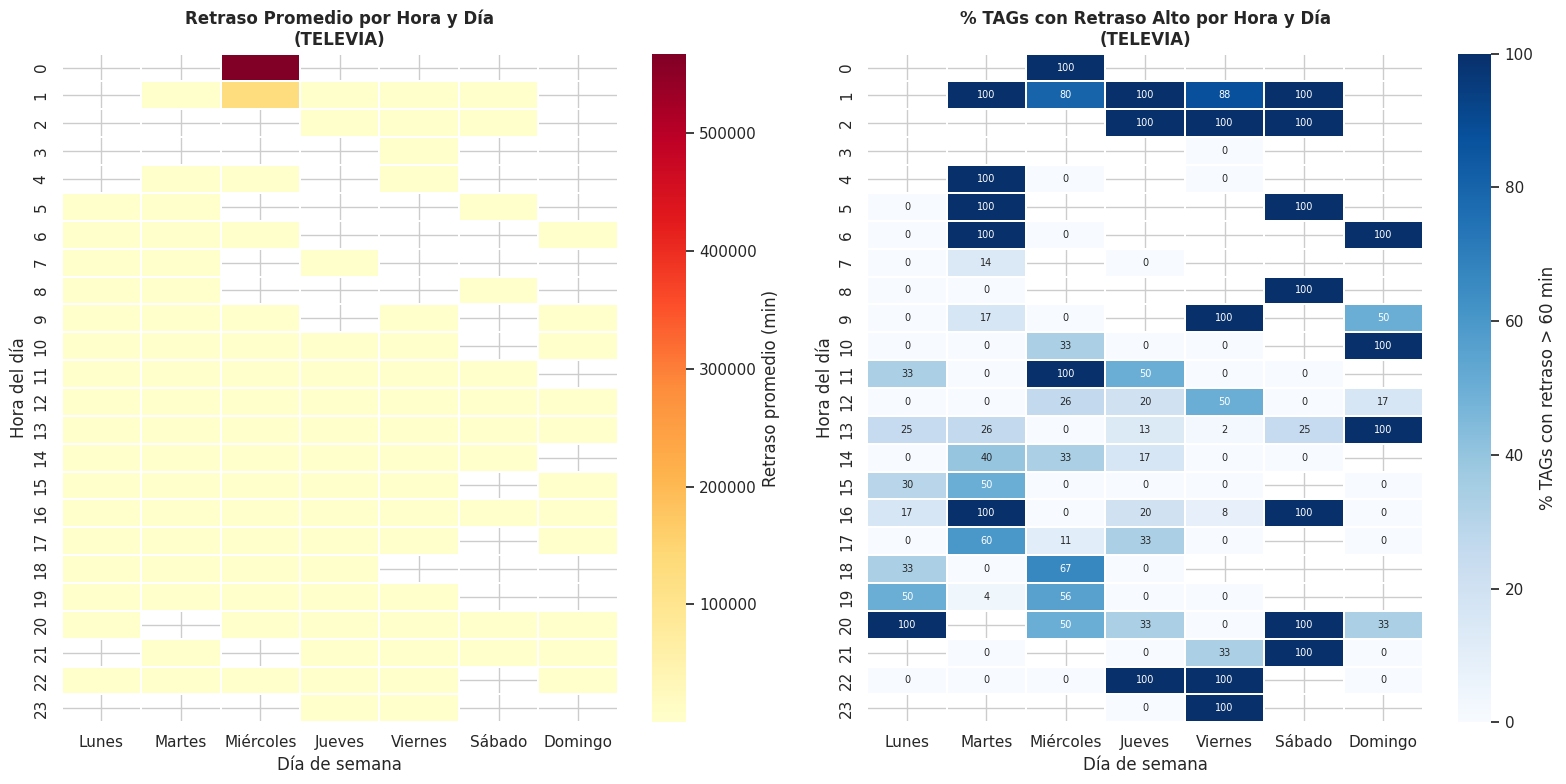

El heatmap revela con precisión las combinaciones día-hora más críticas.
Las celdas más oscuras indican mayor concentración de desfases.


In [7]:
# Pivot: filas=hora, columnas=día, valores=retraso_promedio
pivot = televia.pivot_table(
    index='hora',
    columns='dia_semana',
    values='retraso_promedio',
    aggfunc='mean',
    observed=True
)
pivot = pivot[dias_orden]  # ordenar días lunes→domingo

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Heatmap de retraso promedio
sns.heatmap(pivot, ax=axes[0], cmap='YlOrRd', linewidths=0.3,
            cbar_kws={'label': 'Retraso promedio (min)'},
            fmt='.0f', annot=False)
axes[0].set_title('Retraso Promedio por Hora y Día\n(TELEVIA)', fontweight='bold')
axes[0].set_xlabel('Día de semana')
axes[0].set_ylabel('Hora del día')

# Heatmap de % TAGs con retraso alto
pivot_pct = televia.pivot_table(
    index='hora',
    columns='dia_semana',
    values='pct_retraso_alto',
    aggfunc='mean',
    observed=True
)[dias_orden]

sns.heatmap(pivot_pct, ax=axes[1], cmap='Blues', linewidths=0.3,
            cbar_kws={'label': '% TAGs con retraso > 60 min'},
            fmt='.0f', annot=True, annot_kws={'size': 7})
axes[1].set_title('% TAGs con Retraso Alto por Hora y Día\n(TELEVIA)', fontweight='bold')
axes[1].set_xlabel('Día de semana')
axes[1].set_ylabel('Hora del día')

plt.tight_layout()
plt.show()

print("El heatmap revela con precisión las combinaciones día-hora más críticas.")
print("Las celdas más oscuras indican mayor concentración de desfases.")


## 3. Modelo de Detección de Anomalías sobre TELEVIA

Se aplica nuevamente Isolation Forest, ahora sobre los registros de TELEVIA con la granularidad hora × día. Esto permite identificar no solo que TELEVIA es problemático, sino **exactamente cuándo** ocurren sus peores momentos.


In [8]:
features = ['hora', 'dia_semana_num', 'total_tags', 'retraso_promedio',
            'retraso_maximo', 'tags_con_retraso_alto', 'pct_retraso_alto', 'retraso_desviacion']

X = televia[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

modelo = IsolationForest(contamination=0.05, n_estimators=200, random_state=42)
modelo.fit(X_scaled)

televia = televia.copy()
televia['anomalia'] = modelo.predict(X_scaled)
televia['score_anomalia'] = modelo.score_samples(X_scaled)
televia['etiqueta'] = televia['anomalia'].map({1: 'Normal', -1: 'Anomalía'})

n_anom = (televia['anomalia'] == -1).sum()
print(f"Total registros TELEVIA: {len(televia)}")
print(f"Anomalías detectadas:    {n_anom} ({n_anom/len(televia)*100:.1f}%)")


Total registros TELEVIA: 241
Anomalías detectadas:    12 (5.0%)


### 3.1 Heatmap de anomalías detectadas

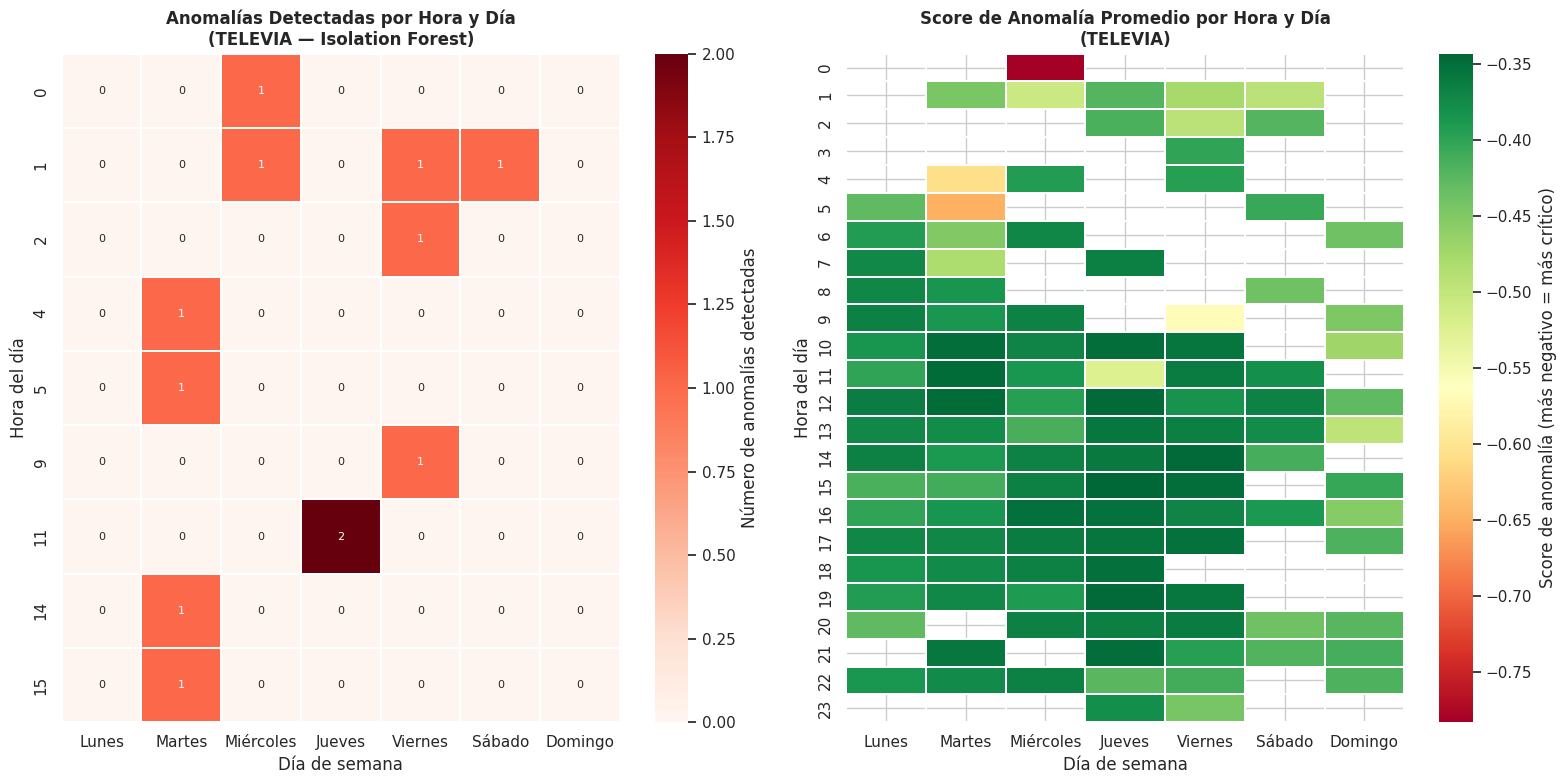

In [9]:
# Contar anomalías por hora y día
pivot_anom = televia[televia['anomalia'] == -1].pivot_table(
    index='hora',
    columns='dia_semana',
    values='anomalia',
    aggfunc='count',
    observed=True
).reindex(columns=dias_orden).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.heatmap(pivot_anom, ax=axes[0], cmap='Reds', linewidths=0.3,
            annot=True, fmt='.0f', annot_kws={'size': 8},
            cbar_kws={'label': 'Número de anomalías detectadas'})
axes[0].set_title('Anomalías Detectadas por Hora y Día\n(TELEVIA — Isolation Forest)', fontweight='bold')
axes[0].set_xlabel('Día de semana')
axes[0].set_ylabel('Hora del día')

# Score promedio de anomalía (más negativo = más anómalo)
pivot_score = televia.pivot_table(
    index='hora',
    columns='dia_semana',
    values='score_anomalia',
    aggfunc='mean',
    observed=True
).reindex(columns=dias_orden)

sns.heatmap(pivot_score, ax=axes[1], cmap='RdYlGn', linewidths=0.3,
            cbar_kws={'label': 'Score de anomalía (más negativo = más crítico)'},
            annot=False)
axes[1].set_title('Score de Anomalía Promedio por Hora y Día\n(TELEVIA)', fontweight='bold')
axes[1].set_xlabel('Día de semana')
axes[1].set_ylabel('Hora del día')

plt.tight_layout()
plt.show()


### 3.2 Casos más críticos

In [10]:
print("=== Top 15 registros más anómalos de TELEVIA ===\n")
cols = ['fecha', 'dia_semana', 'hora', 'total_tags',
        'retraso_promedio', 'retraso_maximo', 'pct_retraso_alto', 'score_anomalia', 'etiqueta']
top = televia.sort_values('score_anomalia').head(15)
print(top[cols].to_string(index=False))


=== Top 15 registros más anómalos de TELEVIA ===

     fecha dia_semana  hora  total_tags  retraso_promedio  retraso_maximo  pct_retraso_alto  score_anomalia etiqueta
2026-06-09     Martes     4     2429059               273            1716        100.000000       -0.784080 Anomalía
2026-04-29  Miércoles     1          81            630405          776628        100.000000       -0.783538 Anomalía
2026-04-29  Miércoles     0         205            567377          776591        100.000000       -0.782734 Anomalía
2026-06-09     Martes     5      481912               296            1723        100.000000       -0.647550 Anomalía
2026-03-26     Jueves    11           4              3609            5007        100.000000       -0.628876 Anomalía
2026-03-05     Jueves    11           4              1076            2176         50.000000       -0.596653 Anomalía
2026-03-06    Viernes     9           7              1522            3427        100.000000       -0.568927 Anomalía
2026-06-09    

### 3.3 Distribución de anomalías por franja horaria

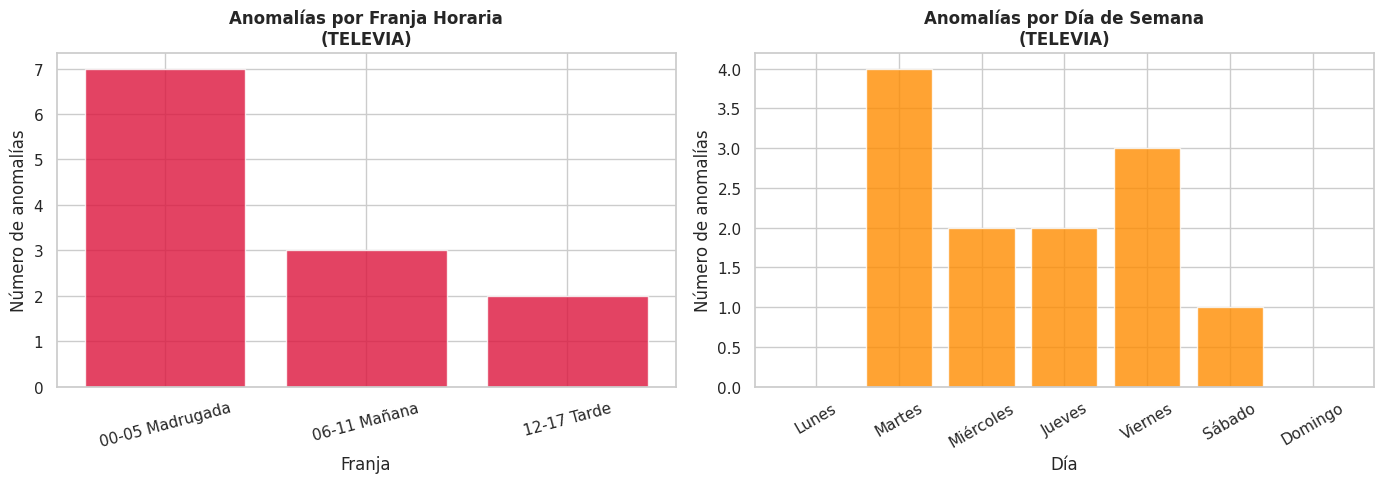


=== Resumen de anomalías por día ===
dia_semana
Lunes        0
Martes       4
Miércoles    2
Jueves       2
Viernes      3
Sábado       1
Domingo      0


In [11]:
# Clasificar horas en franjas
def franja(h):
    if 0 <= h < 6:   return '00-05 Madrugada'
    elif 6 <= h < 12: return '06-11 Mañana'
    elif 12 <= h < 18: return '12-17 Tarde'
    else:             return '18-23 Noche'

televia['franja'] = televia['hora'].apply(franja)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Anomalías por franja
anom_franja = televia[televia['anomalia'] == -1]['franja'].value_counts().sort_index()
axes[0].bar(anom_franja.index, anom_franja.values, color='crimson', alpha=0.8)
axes[0].set_title('Anomalías por Franja Horaria\n(TELEVIA)', fontweight='bold')
axes[0].set_xlabel('Franja')
axes[0].set_ylabel('Número de anomalías')
axes[0].tick_params(axis='x', rotation=15)

# Anomalías por día
anom_dia = televia[televia['anomalia'] == -1]['dia_semana'].value_counts()
anom_dia = anom_dia.reindex(dias_orden).fillna(0)
axes[1].bar(anom_dia.index, anom_dia.values, color='darkorange', alpha=0.8)
axes[1].set_title('Anomalías por Día de Semana\n(TELEVIA)', fontweight='bold')
axes[1].set_xlabel('Día')
axes[1].set_ylabel('Número de anomalías')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print("\n=== Resumen de anomalías por día ===")
print(anom_dia.to_string())


## 4. Conclusiones del Análisis de Profundidad

### Hallazgos principales

1. **TELEVIA concentra retrasos de magnitud excepcional** — varios miles de minutos promedio vs. menos de 5 minutos en el resto de operadores. Esto sugiere un problema sistémico, no incidental.

2. **El miércoles es el día más crítico**, con retrasos promedio muy por encima del resto de días de la semana. Esto puede relacionarse con procesos batch de conciliación que se ejecutan a mitad de semana.

3. **La madrugada (00:00-05:00 hrs) concentra los peores registros**, especialmente las 00:00 y 01:00 hrs. Esto sugiere que los procesos nocturnos de sincronización fallan o se retrasan de forma recurrente.

4. **La combinación miércoles-madrugada es la más crítica** — es el slot donde el modelo asigna los scores de anomalía más negativos.

### Implicación operativa

> Con esta información, el equipo puede priorizar la revisión de los procesos de sincronización de TELEVIA específicamente los **miércoles en la madrugada**, en lugar de monitorear indiscriminadamente los 7 días × 24 horas × 5 operadores.

Esto reduce el espacio de búsqueda de incidencias de **840 combinaciones posibles** a un conjunto acotado de slots de alto riesgo, haciendo el monitoreo preventivo viable y eficiente.
